# VALORA AI: Better Data, Better Predictions
## Notebook 01: data audit and target provenance (Budva appraisal experiment)

**Research question:** *Can richer property data improve the prediction of **appraised** apartment values in Budva and outperform a traditional price-per-square-meter baseline?*

This notebook:
1. loads the appraisal data and checks that the file is the audited version;
2. describes what the target `market_value_eur` represents (and what it does not);
3. builds a data dictionary of all 26 columns;
4. runs every data-quality check (duplicates, areas, values, dates, building age, distances, extreme values, categories, linked appraisals, value basis);
5. saves the audit findings and the modelling table (80 Budva properties);
6. draws the descriptive figures.

**Nothing is deleted silently.** The only row left out of modelling is the single Kotor property, for the reason given below. All other unusual rows are kept and flagged for sensitivity analyses.

The evaluation protocol (`docs/EVALUATION_PROTOCOL.md`) was locked after this audit and before any model was fitted.

**What this code does:** Sets up the project paths and imports the project modules from `src/`.

**Why we need it:** All notebooks use paths relative to the project folder, so the project runs from any location.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'budva_data.py').exists():      # works when started from notebooks/ or from the project root
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Start Jupyter inside the VALORA_BUDVA_APPRAISAL_EXPERIMENT folder')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 90)

import budva_data as bd
import budva_plots as bp
print('project folder found; data folder:', (ROOT / 'data').relative_to(ROOT))

project folder found; data folder: data


## 1. Load the data and verify the file

- **Shareable copy:** the notebooks read `data/raw/VALORA_Budva_appraisals_shareable.csv`. It is identical to the collected file, with two exceptions:
  - property and report numbers are replaced by neutral codes (P001…, G001…) that keep order and equality;
  - the name of one residential complex is replaced.
- **When the collected file is present** (only in the working copy), the shareable copy is regenerated from it and both checksums are verified.

**What this code does:** Regenerates the shareable copy if the collected file is present, verifies the checksum, and loads the data.

**Why we need it:** A checksum guarantees that every result is computed from exactly the audited data.

In [2]:
original = bd.RAW_DIR / bd.ORIGINAL_FILE
if original.exists():
    bd.make_shareable(original)
    print('collected file found: shareable copy regenerated from it')
else:
    print('collected file not included in this package: using the shareable copy')
assert bd.sha256(bd.RAW_DIR / bd.SHAREABLE_FILE) == bd.SHAREABLE_SHA256, 'shareable data file differs from the audited version'
raw = bd.load_raw()
print('rows:', raw.shape[0], '| columns:', raw.shape[1])
print(raw['city'].value_counts().to_string())
raw.head()

collected file found: shareable copy regenerated from it
rows: 81 | columns: 26
city
Budva    80
Kotor     1


,property_id,city,neighborhood,date,area_m2,bedrooms,bathrooms,floor,construction_year,building_age_years,elevator,terrace,air_conditioning,furnished,renovated,orientation,view_type,distance_to_sea_m,distance_to_center_road_m,construction_type,building_permit,registered_encumbrance,market_value_eur,price_per_m2_eur,report_group,value_basis
0,P001,Budva,Rozino,2023-03-20,35,1,1,2,2008,15,1,1,1,0,0,east,courtyard,800,1100,masonry,1,0,65000.0,1857.14,G001,rounded_appraisal
1,P002,Budva,Babilonija,2023-10-19,57,2,2,2,1990,33,0,1,1,0,1,southwest,neighboring_buildings,700,1150,masonry,1,1,98000.0,1719.30,G002,rounded_appraisal
2,P003,Budva,Rafailovići,2026-02-20,45,1,1,1,2025,1,1,1,1,0,0,east,sea,160,4500,frame,1,0,178839.0,3974.20,G003,allocated_appraisal
3,P004,Budva,Rafailovići,2026-02-20,47,1,1,1,2025,1,1,1,1,0,0,east,sea,160,4500,frame,1,0,186787.4,3974.20,G003,allocated_appraisal
4,P005,Budva,Rafailovići,2026-02-20,39,1,1,3,2025,1,1,1,1,0,0,east,sea,160,4500,frame,1,0,154993.8,3974.20,G003,allocated_appraisal


## 2. What does the target represent?

The target `market_value_eur` is the **market value stated by a professional appraiser** in a valuation report. Three price concepts must be kept apart:

| Concept | Source | Used in |
|---|---|---|
| **Asking price** | what a seller advertises | the original VALORA AI models (national and regional) |
| **Appraised market value** | an appraiser's professional opinion of value at a valuation date | **this experiment** |
| **Transaction price** | the price actually paid and registered | not available in either dataset |

- **Appraised values are not confirmed sale prices.** Appraisers base them on comparable sales or offers, so they tend to be smoother than asking prices.
- **The MAE of this experiment cannot be compared with the asking-price models.** The samples and the target definitions differ. Every comparison is made **inside** the Budva data, on the same properties and the same folds.

The column `value_basis` records how each value was formed. The table below shows what each label means.

**What this code does:** Counts the value bases and shows how the target was formed in each case.

**Why we need it:** Allocated or conditional values may be less reliable or not independent, which matters for validation.

In [3]:
basis_meaning = {
    'rounded_appraisal': 'the appraiser\'s final value for this apartment, rounded',
    'allocated_appraisal': 'a joint value for several units, split between them by area',
    'rounded_appraisal_review': 'a rounded value from a review of an earlier appraisal',
    'combined_apartment_appraisal': 'one value for apartments combined into one unit',
    'conditional_legalization_appraisal': 'value assuming the legalisation of the property is completed',
}
vb = raw['value_basis'].value_counts().rename('properties').to_frame()
vb['meaning'] = vb.index.map(basis_meaning)
vb

,properties,meaning
value_basis,,
rounded_appraisal,66,"the appraiser's final value for this apartment, rounded"
allocated_appraisal,9,"a joint value for several units, split between them by area"
rounded_appraisal_review,4,a rounded value from a review of an earlier appraisal
combined_apartment_appraisal,1,one value for apartments combined into one unit
conditional_legalization_appraisal,1,value assuming the legalisation of the property is completed


**What this code does:** Shows the reports that contain more than one property, with their €/m².

**Why we need it:** Allocated values inside one report share the same €/m², so they are derived from one appraisal and are not independent observations.

In [4]:
multi = raw[raw.groupby('report_group')['property_id'].transform('size') > 1]
multi[['property_id', 'report_group', 'neighborhood', 'date', 'area_m2', 'market_value_eur', 'price_per_m2_eur', 'value_basis']]

,property_id,report_group,neighborhood,date,area_m2,market_value_eur,price_per_m2_eur,value_basis
2,P003,G003,Rafailovići,2026-02-20,45,178839.00,3974.20,allocated_appraisal
3,P004,G003,Rafailovići,2026-02-20,47,186787.40,3974.20,allocated_appraisal
4,P005,G003,Rafailovići,2026-02-20,39,154993.80,3974.20,allocated_appraisal
17,P018,G016,Zavala,2026-04-23,76,323307.80,4254.05,allocated_appraisal
18,P019,G016,Zavala,2026-04-23,190,737000.00,3878.95,rounded_appraisal
27,P028,G025,Budva,2022-06-09,24,47106.74,1962.78,allocated_appraisal
28,P029,G025,Budva,2022-06-09,47,90751.11,1930.87,allocated_appraisal


**Provenance:**
- **Values within a report are not independent.**
  - In one report, three units have exactly the same €/m². Their values were obtained by splitting one joint value by area.
  - In another, one unit is allocated and one is a rounded value.
- **No property appears in two reports.** Some buildings, however, were appraised several times on different dates.
- **Method:** the reports state market values formed by the appraiser. The data do not record whether the comparison, income or cost approach was used for each property. This is a documented limitation.

## 3. Data dictionary

The table below lists, for each of the 26 columns, its type, meaning, number of unique values, missing values, range, potential issues and the decision taken.

**What this code does:** Builds the data dictionary and saves it to `results/data_dictionary.csv`.

**Why we need it:** Every column needs a documented decision before modelling: feature, target, grouping, filter or excluded.

In [5]:
dictionary = bd.data_dictionary(raw)
dictionary.to_csv(bd.RESULTS_DIR / 'data_dictionary.csv', index=False, encoding='utf-8', lineterminator='\n')
dictionary

,column,type,pandas dtype,meaning,unique values,missing,range,potential issues,decision
0,property_id,identifier,str,Neutral property code (P001…),81,0,,None,Not a predictor (identifier)
1,city,categorical,str,Municipality of the property,2,0,,"80 Budva, 1 Kotor",Filter: Budva only
2,neighborhood,categorical,str,"Neighbourhood, settlement or named complex",25,0,,"many names with a single property; ""Budva"" (3 rows) is not a neighbourhood",Feature (after fixed harmonisation)
3,date,date,str,Date of the appraisal (valuation date),67,0,,No 2024 appraisals,Appraisal year as a feature; temporal split
4,area_m2,numeric,int64,Usable area of the apartment (m²),55,0,24 – 190,None found,Feature (all sets)
5,bedrooms,integer,int64,Number of bedrooms (0 = studio),5,0,0 – 4,Strongly tied to area,Feature (set C)
6,bathrooms,integer,int64,Number of bathrooms,3,0,1 – 3,Strongly tied to area,Feature (set C)
7,floor,integer,int64,"Floor (-1 = below ground, 0 = ground)",10,0,-1 – 9,One property at -1,Feature (set C)
8,construction_year,integer,int64,Year the building was built (or is planned to be finished),21,0,1980 – 2025,Later than the appraisal year for 2 properties,Not used: redundant with building age
9,building_age_years,integer,int64,"Building age at the appraisal date, 0 if not finished",29,0,0 – 45,Consistent with date and construction year,Feature (set C)


## 4. Data quality checks

Each check below is also recorded in the audit table in section 5.

**What this code does:** Checks duplicates, missing values, dates, areas and the consistency of `price_per_m2_eur`.

**Why we need it:** Basic validity checks come first; a derived column that equals the target divided by area must never be a predictor.

In [6]:
d = bd.add_derived(raw)
content_cols = [c for c in raw.columns if c != 'property_id']
print('exact duplicate rows (ignoring the id):', int(raw.duplicated(content_cols).sum()))
print('duplicate property ids:', int(raw['property_id'].duplicated().sum()))
print('missing cells:', int(raw.isna().sum().sum()))
print('dates:', d['date'].min().date(), 'to', d['date'].max().date(), '| unparseable:', int(d['date'].isna().sum()))
print('appraisals per year:', d['appraisal_year'].value_counts().sort_index().to_dict())
print('area range (m²):', raw['area_m2'].min(), '-', raw['area_m2'].max())
ppm = raw['market_value_eur'] / raw['area_m2']
print('rows where price_per_m2_eur differs from value / area by more than €0.02:',
      int(((ppm.round(2) - raw['price_per_m2_eur']).abs() > 0.02).sum()))

exact duplicate rows (ignoring the id): 0
duplicate property ids: 0
missing cells: 0
dates: 2021-04-20 to 2026-10-20 | unparseable: 0
appraisals per year: {2021: 4, 2022: 12, 2023: 16, 2025: 27, 2026: 22}
area range (m²): 24 - 190
rows where price_per_m2_eur differs from value / area by more than €0.02: 0


**What this code does:** Lists the properties whose construction year is later than the appraisal year, and checks the building age column.

**Why we need it:** A building cannot be older than zero years at the appraisal; these cases need an explanation, not deletion.

In [7]:
late = d[d['under_construction_at_appraisal'] == 1]
print(late[['property_id', 'neighborhood', 'date', 'construction_year', 'building_age_years', 'market_value_eur', 'price_per_m2_eur']].to_string(index=False))
age_ok = (d['appraisal_year'] - d['construction_year']).clip(lower=0) == d['building_age_years']
print('\nrows where age ≠ max(0, appraisal year − construction year):', int((~age_ok).sum()))

property_id neighborhood       date  construction_year  building_age_years  market_value_eur  price_per_m2_eur
       P031  Rafailovići 2022-07-11               2025                   0           69000.0           1642.86
       P041  Rafailovići 2023-08-07               2025                   0           90000.0           1698.11

rows where age ≠ max(0, appraisal year − construction year): 0


**Interpretation:**
- **Two appraisals were made before the building was finished.** The building was completed in 2025, while the valuations date from 2022 and 2023. The age is recorded as 0, which is consistent.
- **Their €/m² is low** compared with later appraisals in the same building. This is plausible for valuations made during construction and in an earlier, cheaper market.
- **Both rows are kept.** Building age (not construction year) is the feature, because age at the appraisal date is what an appraiser would use.

**What this code does:** Summarises the distances and checks how much they vary inside each neighbourhood.

**Why we need it:** If distances are mostly one value per neighbourhood, they add little information beyond the neighbourhood itself.

In [8]:
bud = d[d['city'] == 'Budva']
print(bud[['distance_to_sea_m', 'distance_to_center_road_m']].describe().round(0).to_string())
per_nb = bud.groupby('neighborhood_group').agg(properties=('property_id', 'size'),
                                                sea_values=('distance_to_sea_m', 'nunique'),
                                                centre_values=('distance_to_center_road_m', 'nunique'))
print()
print(per_nb[per_nb['properties'] >= 2].sort_values('properties', ascending=False).to_string())

       distance_to_sea_m  distance_to_center_road_m
count               80.0                       80.0
mean               562.0                     2459.0
std                303.0                     2960.0
min                 90.0                       50.0
25%                300.0                     1050.0
50%                550.0                     1275.0
75%                812.0                     3200.0
max               1400.0                    17000.0

                    properties  sea_values  centre_values
neighborhood_group                                       
Bečići                      17           9              4
Rafailovići                  8           1              1
Rozino                       8           3              2
Podkošljun                   5           3              1
Centar                       5           2              1
Old Bakery                   5           1              1
Babilonija                   3           2              1
Bulevar /

**What this code does:** Shows the most valuable properties and the €/m² outliers.

**Why we need it:** A few expensive properties can dominate an MAE; they are kept and examined in a sensitivity analysis.

In [9]:
bud = bud.assign(ppm=bud['market_value_eur'] / bud['area_m2'])
cols = ['property_id', 'neighborhood', 'date', 'area_m2', 'view_type', 'market_value_eur', 'ppm', 'value_basis']
print('Top 5% by value:')
print(bud.nlargest(4, 'market_value_eur')[cols].round({'ppm': 0}).to_string(index=False))
q1, q3 = bud['ppm'].quantile([.25, .75])
print(f'\n€/m² IQR fences: €{q1 - 1.5 * (q3 - q1):,.0f} – €{q3 + 1.5 * (q3 - q1):,.0f}')
print(bud[(bud['ppm'] > q3 + 1.5 * (q3 - q1)) | (bud['ppm'] < q1 - 1.5 * (q3 - q1))][cols].round({'ppm': 0}).to_string(index=False))

Top 5% by value:
property_id neighborhood       date  area_m2 view_type  market_value_eur    ppm       value_basis
       P019       Zavala 2026-04-23      190       sea          737000.0 3879.0 rounded_appraisal
       P065  Rafailovići 2025-01-29      102       sea          490000.0 4804.0 rounded_appraisal
       P033       Centar 2022-08-12      117     urban          482000.0 4120.0 rounded_appraisal
       P017 Sveti Stefan 2026-05-26      131       sea          409000.0 3122.0 rounded_appraisal

€/m² IQR fences: €-111 – €4,760
property_id neighborhood       date  area_m2 view_type  market_value_eur    ppm       value_basis
       P065  Rafailovići 2025-01-29      102       sea          490000.0 4804.0 rounded_appraisal


**What this code does:** Counts the categories of every categorical and binary column.

**Why we need it:** Columns with almost no variation cannot be learned from 80 properties and may be default entries.

In [10]:
for c in ['neighborhood', 'view_type', 'orientation', 'construction_type', 'elevator', 'terrace', 'air_conditioning',
          'furnished', 'renovated', 'building_permit', 'registered_encumbrance', 'bedrooms', 'bathrooms', 'floor']:
    print(f'{c:24s}', raw[c].value_counts().to_dict())

neighborhood             {'Bečići': 16, 'Rozino': 8, 'Rafailovići': 8, 'Old Bakery': 5, 'Centar': 5, 'Podkošljun': 5, 'Babilonija': 3, 'Budva': 3, 'Obilaznica': 3, 'Bulevar / Nivel': 3, 'Petrovac': 2, 'Sveti Stefan': 2, 'Zavala': 2, 'Babin Do': 2, 'Mainski put': 2, 'Dubovica Lux': 2, 'Elmosove zgrade': 2, 'Lastva Grbaljska - Jaz': 1, 'Prijevor - Seoce': 1, 'Adok': 1, 'Dubovica': 1, 'Gospoština': 1, 'Bečići – named complex': 1, 'Podmaine': 1, 'Golubovina': 1}
view_type                {'urban': 59, 'sea': 17, 'neighboring_buildings': 3, 'courtyard': 2}
orientation              {'east': 79, 'southwest': 2}
construction_type        {'masonry': 49, 'frame': 32}
elevator                 {1: 60, 0: 21}
terrace                  {1: 78, 0: 3}
air_conditioning         {1: 81}
furnished                {0: 79, 1: 2}
renovated                {0: 77, 1: 4}
building_permit          {1: 79, 0: 2}
registered_encumbrance   {0: 72, 1: 9}
bedrooms                 {2: 38, 1: 29, 3: 9, 0: 4, 4: 1}
bathrooms

**Categories:**
- **Excluded:**
  - `air_conditioning` is constant;
  - `orientation` is "east" for 79 of 81 rows, which looks like a default entry rather than a measurement.
- **Kept in feature set C, but they carry little information:** `terrace`, `furnished`, `renovated` and `building_permit` each have only 2-4 minority cases.
- **Not a neighbourhood:** "Budva" (3 rows) is the town name. It is kept as its own category.

**What this code does:** Builds the valuation clusters: properties from the same report, or from the same building appraised on the same day.

**Why we need it:** Cross-validation must keep related appraisals together; otherwise a model could be tested on a value derived from its own training data.

In [11]:
linked = d[d.groupby('valuation_cluster')['report_group'].transform('nunique') > 1]
print(linked[['property_id', 'report_group', 'valuation_cluster', 'neighborhood', 'date', 'construction_year', 'area_m2', 'price_per_m2_eur', 'value_basis']].to_string(index=False))
print()
print('Budva properties:', int((d['city'] == 'Budva').sum()))
print('appraisal reports:', d.loc[d['city'] == 'Budva', 'report_group'].nunique())
print('valuation clusters (independence unit):', d.loc[d['city'] == 'Budva', 'valuation_cluster'].nunique())
print('buildings (neighbourhood + construction year):', d.loc[d['city'] == 'Budva', 'building_key'].nunique())

property_id report_group valuation_cluster    neighborhood       date  construction_year  area_m2  price_per_m2_eur         value_basis
       P010         G008              C008    Sveti Stefan 2026-05-26               2014       90           2333.33   rounded_appraisal
       P017         G015              C008    Sveti Stefan 2026-05-26               2014      131           3122.14   rounded_appraisal
       P078         G074              C073 Bulevar / Nivel 2023-12-12               2017      103           2969.71 allocated_appraisal
       P079         G075              C073 Bulevar / Nivel 2023-12-12               2017      117           2821.23 allocated_appraisal
       P080         G076              C073 Bulevar / Nivel 2023-12-12               2017      112           2969.71 allocated_appraisal

Budva properties: 80
appraisal reports: 76
valuation clusters (independence unit): 73
buildings (neighbourhood + construction year): 40


**Independence:**
- **80 properties are not 80 independent appraisals.**
  - They come from **76 reports**.
  - Two groups of reports describe flats in the same building valued on the same day. One of them shares the same €/m² for two units, which suggests one underlying valuation.
  - The conservative independence unit is therefore the **73 valuation clusters**.
- **Repeated buildings:** several buildings were appraised again at other dates. Those are separate valuations and legitimate comparables. A sensitivity analysis groups by building as well.

## 5. Audit table

Every finding is saved to `results/audit_findings.csv`.

**What this code does:** Runs all audit checks together and saves the table.

**Why we need it:** One table documents every finding and its decision, so nothing is removed without a reason.

In [12]:
findings = bd.audit_findings(raw)
findings.to_csv(bd.RESULTS_DIR / 'audit_findings.csv', index=False, encoding='utf-8', lineterminator='\n')
findings[['check', 'properties', 'detail', 'decision']]

,check,properties,detail,decision
0,Exact duplicate rows (all columns except the id),0,none found,nothing to remove
1,Duplicate property ids,0,none found,-
2,Missing values,0,0 missing cells,-
3,Invalid or out-of-range dates (outside 2021-01-01 … 2026-12-31),0,dates from 2021-04-20 to 2026-10-20; no appraisal in 2024,keep all
4,Very small or very large area (< 25 m² or > 180 m²),2,plausible: a 24 m² studio and a 190 m² apartment,keep (sensitivity: most valuable properties)
5,price_per_m2_eur equals market_value_eur / area_m2 (± €0.02),0,all rows consistent: the column is derived from the target,never used as a predictor
6,€/m² outside the 1.5 × IQR fences,1,"fences €-123 – €4,749 per m²",keep: no evidence of an error
7,Most valuable properties (top 5% of Budva values),4,"values €409,000, €737,000, €482,000, €490,000",keep (sensitivity analysis without them)
8,Construction year later than the appraisal year,2,building finished after the appraisal (valued while under construction); age recorded ...,keep; age 0 is consistent with the data
9,"building_age_years ≠ max(0, appraisal year − construction year)",0,none: the age column is consistent,"use age, drop construction year (redundant)"


## 6. The modelling table

- **Modelled:** only the **80 Budva properties**.
- **Left out:** the single Kotor property. One observation cannot support a Kotor model, and adding it to Budva would mix a second market with no comparables.
- **Nothing else is removed.**

**What this code does:** Creates the modelling table with the derived columns and saves it to `data/processed/`.

**Why we need it:** All later notebooks start from this one table.

In [13]:
m = bd.model_table(raw)
bd.save_model_table(m)
print('modelling table:', m.shape, '| removed rows:', len(raw) - len(m), '(Kotor)')
print(m[['area_m2', 'market_value_eur']].describe().round(0).to_string())

modelling table: (80, 31) | removed rows: 1 (Kotor)
       area_m2  market_value_eur
count     80.0              80.0
mean      66.0          167192.0
std       30.0          116310.0
min       24.0           43000.0
25%       46.0           89750.0
50%       58.0          140000.0
75%       79.0          210500.0
max      190.0          737000.0


## 7. Descriptive figures

**What this code does:** Draws the data-quality overview.

**Why we need it:** One picture summarises the audit for the presentation.

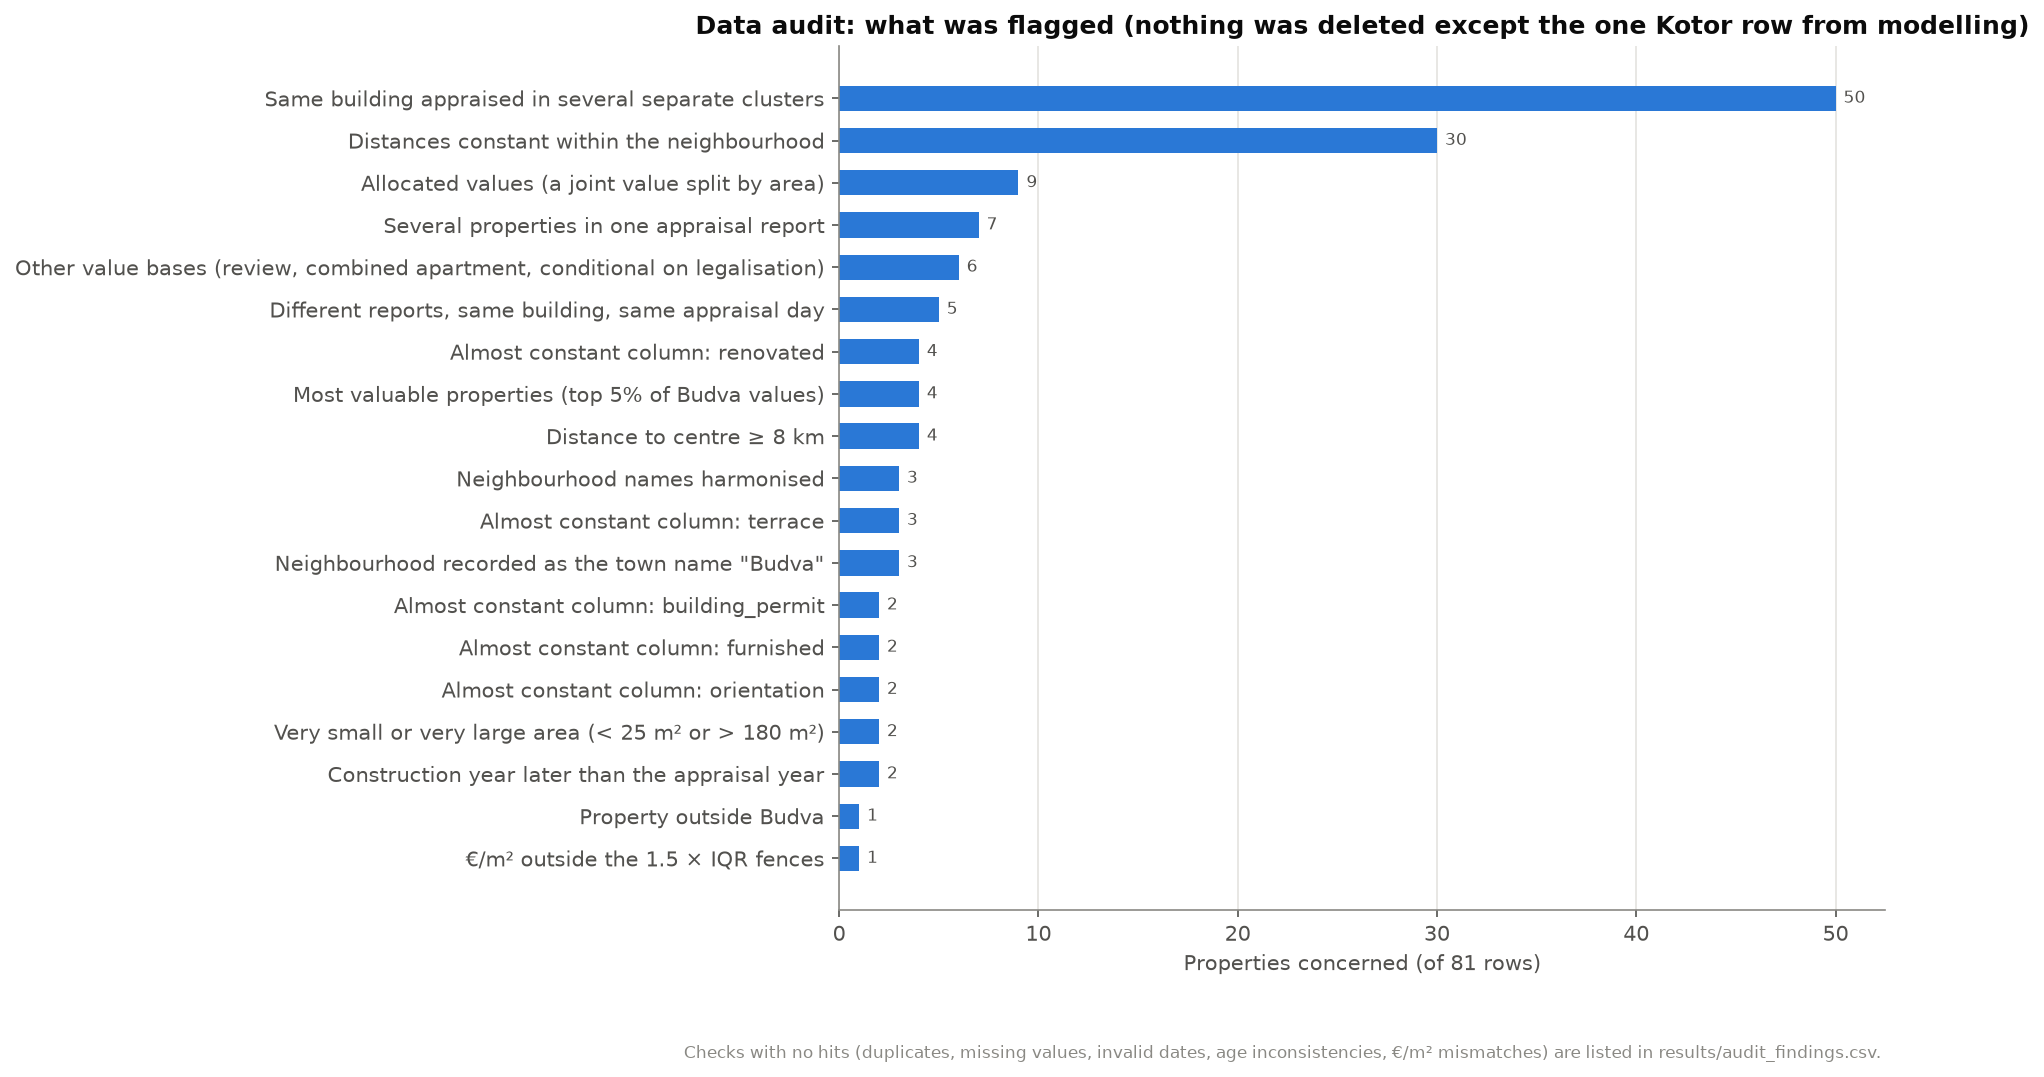

In [14]:
display(Image(bp.data_quality_overview(findings, len(raw))))

**What this code does:** Draws the distribution of appraised values and of €/m², including €/m² by appraisal year.

**Why we need it:** The shape of the target and its rise over time explain the choice of baselines and of the year feature.

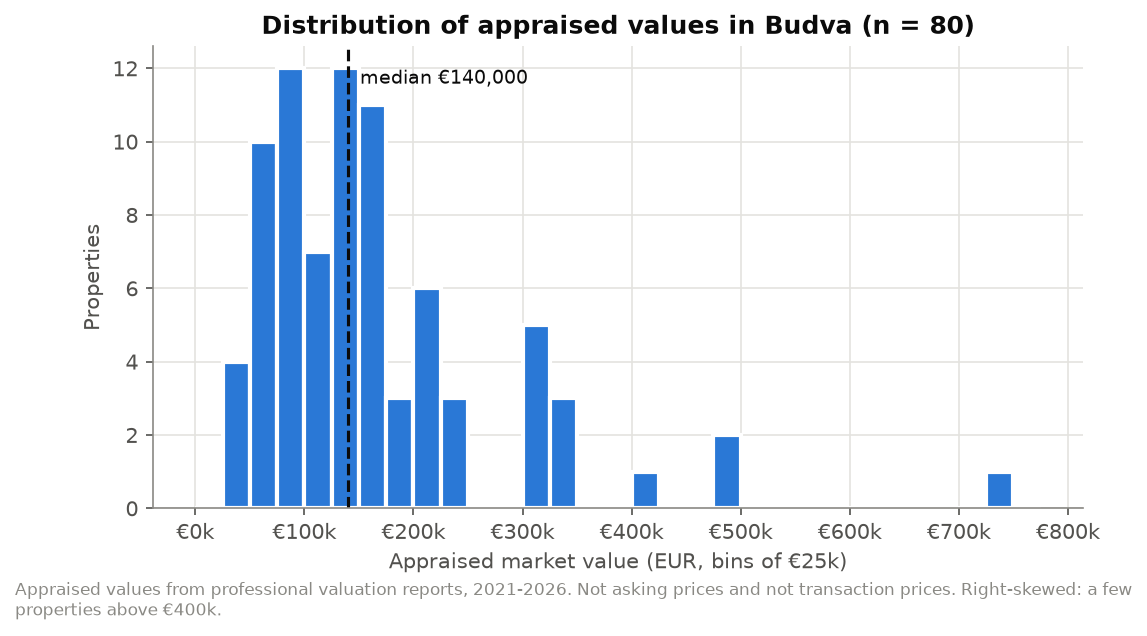

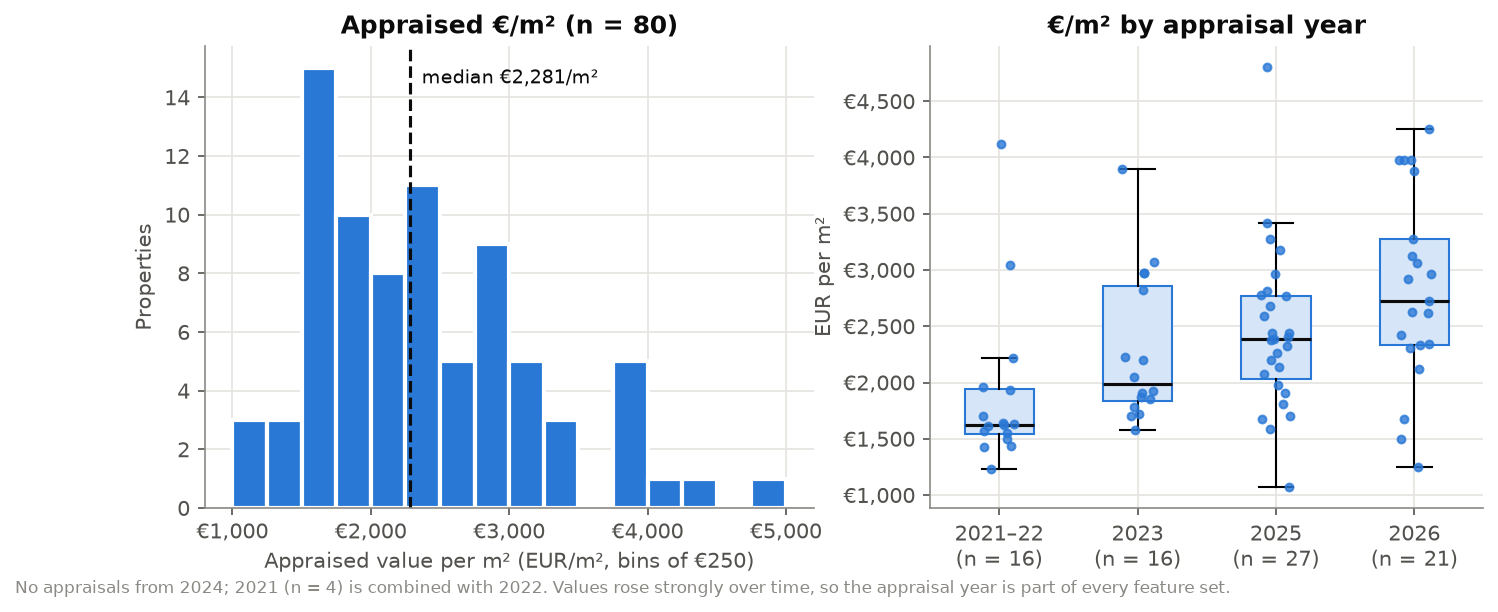

In [15]:
display(Image(bp.value_distribution(m)))
display(Image(bp.ppm2_by_period(m)))

**What this code does:** Draws value versus area, €/m² by neighbourhood and €/m² versus distance to the sea.

**Why we need it:** These show which characteristics might carry information beyond area.

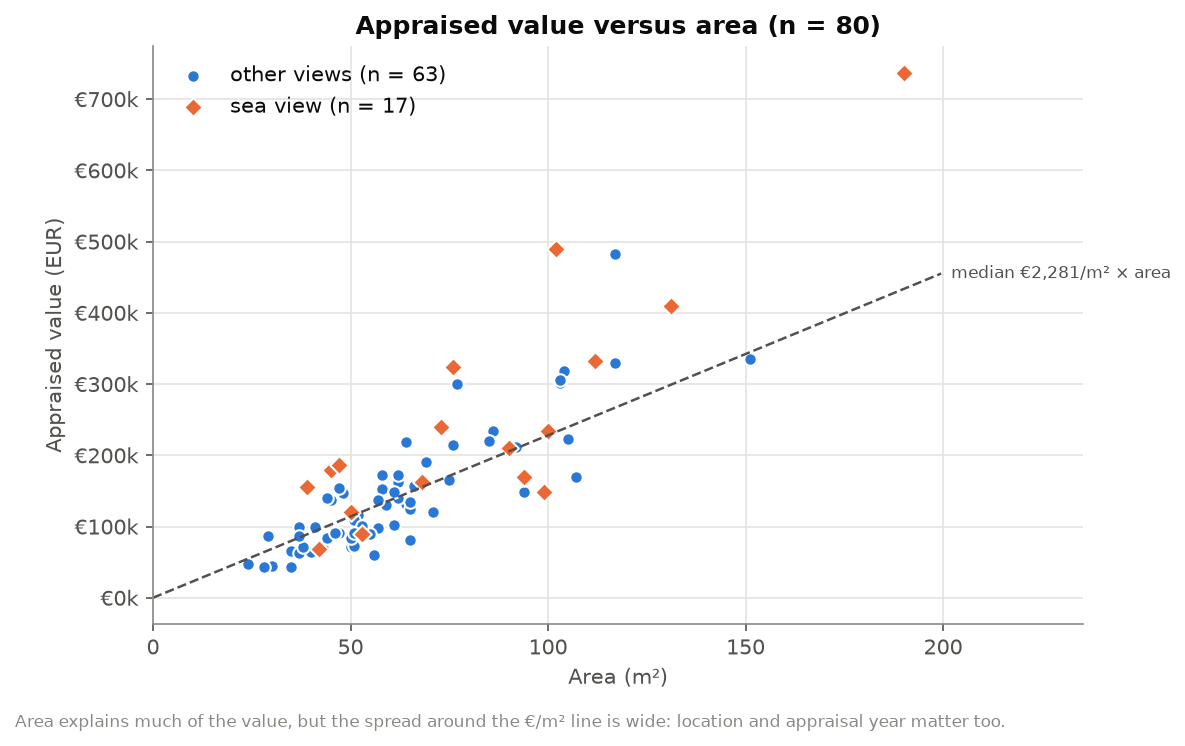

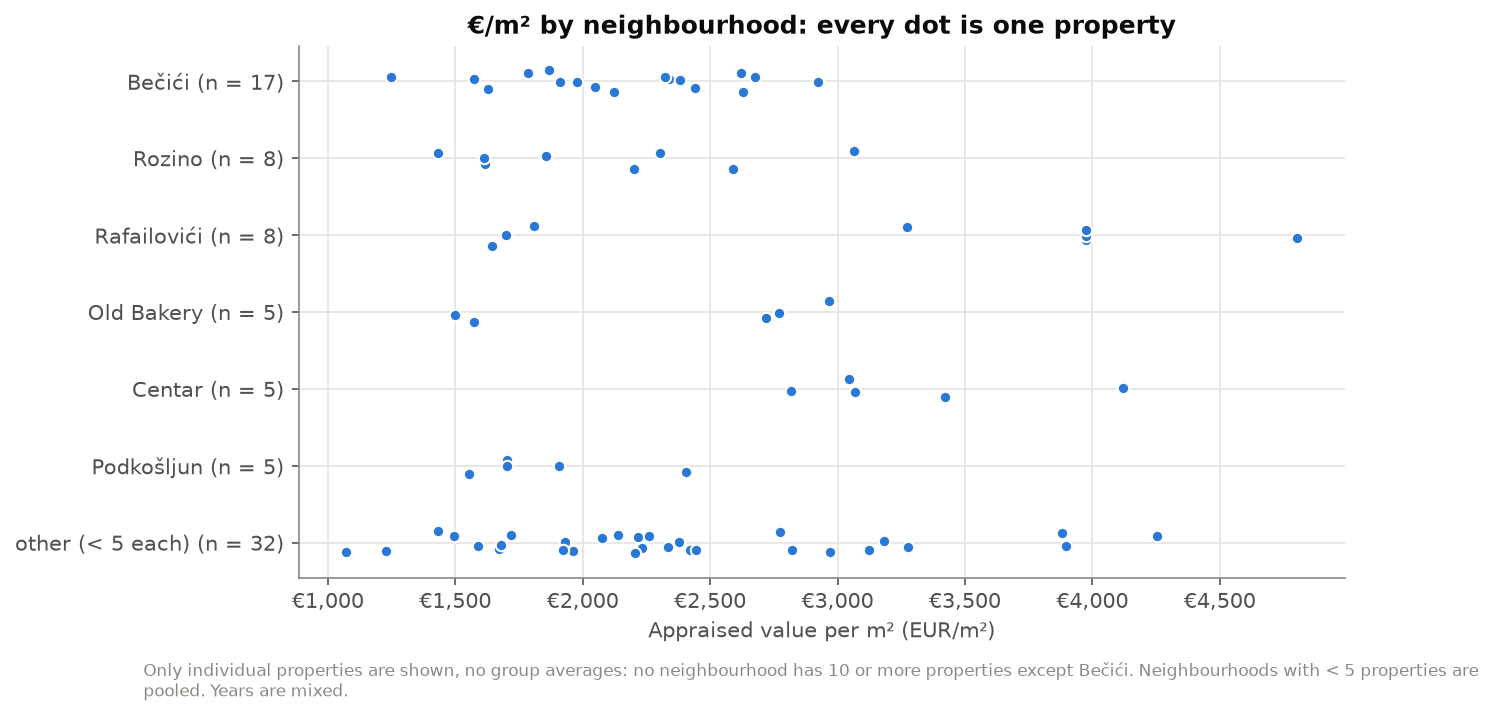

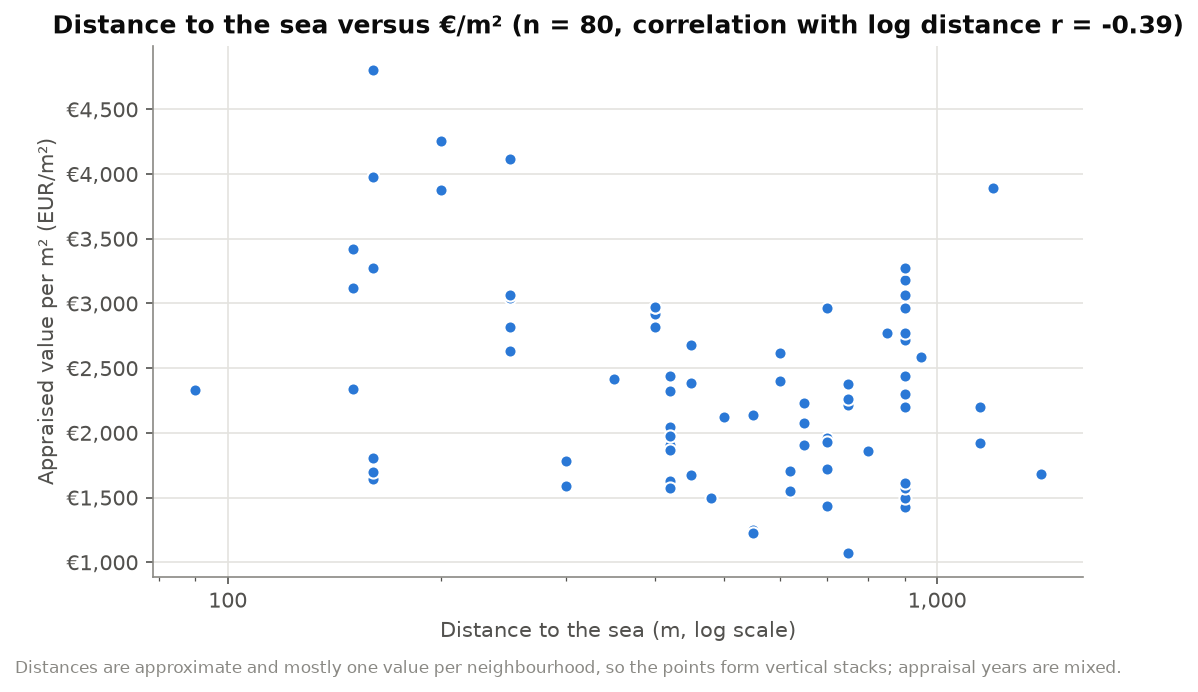

In [16]:
display(Image(bp.value_vs_area(m)))
display(Image(bp.by_neighbourhood(m)))
display(Image(bp.distance_to_sea(m)))

**What this code does:** Prints the key descriptive numbers used in the documents.

**Why we need it:** The documents quote these numbers; printing them here makes them traceable.

In [17]:
ppm = m['market_value_eur'] / m['area_m2']
by_year = m.assign(ppm=ppm).groupby('appraisal_year')['ppm'].median().round(0)
print('median value: €{:,.0f} | median €/m²: €{:,.0f} | median area: {:.0f} m²'.format(
      m['market_value_eur'].median(), ppm.median(), m['area_m2'].median()))
print('median €/m² by year:', by_year.to_dict())
print('sea view:', int((m['view_type'] == 'sea').sum()), 'properties')

median value: €140,000 | median €/m²: €2,281 | median area: 58 m²
median €/m² by year: {2021: 1563.0, 2022: 1673.0, 2023: 1985.0, 2025: 2382.0, 2026: 2721.0}
sea view: 17 properties


## 8. Audit conclusions

1. **The data are clean in the technical sense:** no missing values, no duplicates, valid dates, a consistent building age and a consistent €/m² column.
2. **The target is an appraised value**, sometimes allocated from a joint appraisal, and never a confirmed sale price.
3. **`price_per_m2_eur` is the target divided by area.** Using it as a predictor would be direct leakage.
4. **There are 80 Budva properties but only 73 independent valuation clusters.** All validation is grouped by these clusters.
5. **Several "rich" features carry little information.**
   - Some are almost constant: terrace, furnished, renovated, permit, orientation and air conditioning.
   - The distances largely repeat the neighbourhood.
   - This is a warning sign for the richer feature sets, documented **before** modelling.
6. **Values rose strongly between 2021 and 2026,** so the appraisal year is part of every feature set and of one baseline.